# BCWP


In [ ]:
!pip install pyspark

In [2]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 49.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 48.5 MB/s eta 0:00:00


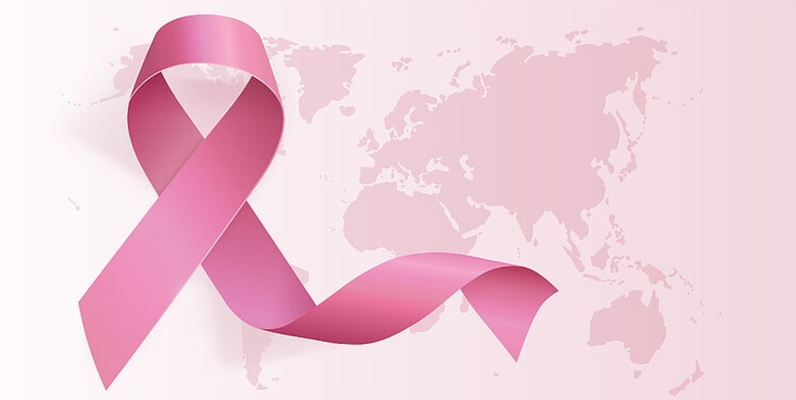

## Importing Package

In [3]:
# Import packages
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyspark
import seaborn as sns
import numpy as np
import pandas as pd
import streamlit as st
import joblib

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator
)

from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression

print(Pipeline.__module__)

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler as SklearnStandardScaler
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
# from sklearn.pipeline import Pipeline


from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    recall_score,
    precision_score,
    f1_score
)

from sklearn.metrics import confusion_matrix, classification_report
from google.colab import files

import warnings
warnings.filterwarnings("ignore")


pyspark.ml.pipeline


### Mount Google Drive
To access your files from Google Drive, we first need to mount it to this Colab notebook runtime.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Initialize SparkSession and Load Data
Now, we initialize a PySpark session and load a CSV dataset (or another file format) from your mounted Google Drive.

In [5]:


# Start a Spark session

spark = SparkSession.builder \
    .master("local[*]")\
    .appName("BreastCancerWinsconsin") \
    .getOrCreate()

In [7]:
# Print messages from Spark session import
spark.sparkContext.setLogLevel("WARN")

print("Spark version:", spark.version)
print("Spark session started successfully!")

Spark version: 4.0.4
Spark session started successfully!


In [8]:
# Import data path

file_path = "/content/drive/MyDrive/AI_DS_ML PROJECTS/BREAST CANCER WISCONSIN/wdbc.data"



# Split into directory and filename
folder, filename = os.path.split(file_path)
print(folder)    # /content/drive/MyDrive/AI_DS_ML PROJECTS/BREAST CANCER WINSCONSIN
print(filename)  # wdbc.data

# Join them back together
full_path = os.path.join(folder, filename)
print(full_path == file_path)  # True

print(f"Setup complete. Update file_path to your file in Drive: {file_path}")

/content/drive/MyDrive/AI_DS_ML PROJECTS/BREAST CANCER WISCONSIN
wdbc.data
True
Setup complete. Update file_path to your file in Drive: /content/drive/MyDrive/AI_DS_ML PROJECTS/BREAST CANCER WISCONSIN/wdbc.data


In [9]:
# List the columns in the data
columns = [
    "id", "diagnosis",
    # Mean values
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean",
    "concave_points_mean", "symmetry_mean", "fractal_dimension_mean",
    # Standard error values
    "radius_se", "texture_se", "perimeter_se", "area_se",
    "smoothness_se", "compactness_se", "concavity_se",
    "concave_points_se", "symmetry_se", "fractal_dimension_se",
    # Worst values
    "radius_worst", "texture_worst", "perimeter_worst", "area_worst",
    "smoothness_worst", "compactness_worst", "concavity_worst",
    "concave_points_worst", "symmetry_worst", "fractal_dimension_worst",
]

In [10]:
# Get the feature list and the label, and then read the data

feature_names = [
    f"{feature}_{stat}"
    for stat in ["mean", "se", "worst"]
    for feature in [
        "radius", "texture", "perimeter", "area",
        "smoothness", "compactness", "concavity",
        "concave_points", "symmetry", "fractal_dimension"
    ]
]

columns = ["id", "diagnosis"] + feature_names

wbc_df = pd.read_csv(
    full_path,
    header=None,
    names=columns
)


In [11]:
# Load the data
wbc_df = pd.read_csv(full_path, header=None, names=columns)

In [ ]:
# Load the data using PySpark
# df = spark.read.csv(file_path, header=False, inferSchema=True)
# display(df.limit(5).toPandas())
# Though an alternative way of reading the data into Colab
# But we won't use it in this case, since the data used
# does not have column names in it directly, and
# Spark’s CSV reader doesn’t take a list of names
#  directly the way pandas does.

In [12]:
# Inspect the first few rows of the data
wbc_df.head(3)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


In [13]:
# Inspect the last few rows of the data
wbc_df.tail(3)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039


In [14]:
# Check the shape of the data
print("Dataset shape:", wbc_df.shape)

Dataset shape: (569, 32)


In [15]:
# Remove the identifier: it is not a predictive feature
wbc_df = wbc_df.drop(columns=["id"])

# Convert diagnosis to a numeric target:
# Malignant = 1, Benign = 0
wbc_df["label"] = (
    wbc_df["diagnosis"]
    .map({"M": 1, "B": 0})
    .astype("int")
)

# Remove the diagnosis column
wbc_df = wbc_df.drop(columns=["diagnosis"])

# Ensure all feature columns are numeric
wbc_df[feature_names] = wbc_df[feature_names].apply(
    pd.to_numeric,
    errors="coerce"
)




In [16]:
# Check for missing values before training
print("Missing values:", int(wbc_df.isna().sum().sum()))
print("Duplicate rows:", int(wbc_df.duplicated().sum()))

# Remove rows with missing values, if any
wbc_df = wbc_df.dropna().copy()

Missing values: 0
Duplicate rows: 0


In [17]:
# Convert Pandas DataFrame to Spark DataFrame
spark_df = spark.createDataFrame(wbc_df)

print("Spark DataFrame row count:", spark_df.count())
spark_df.printSchema()
spark_df.show(5, truncate=False)

Spark DataFrame row count: 569
root
 |-- radius_mean: double (nullable = true)
 |-- texture_mean: double (nullable = true)
 |-- perimeter_mean: double (nullable = true)
 |-- area_mean: double (nullable = true)
 |-- smoothness_mean: double (nullable = true)
 |-- compactness_mean: double (nullable = true)
 |-- concavity_mean: double (nullable = true)
 |-- concave_points_mean: double (nullable = true)
 |-- symmetry_mean: double (nullable = true)
 |-- fractal_dimension_mean: double (nullable = true)
 |-- radius_se: double (nullable = true)
 |-- texture_se: double (nullable = true)
 |-- perimeter_se: double (nullable = true)
 |-- area_se: double (nullable = true)
 |-- smoothness_se: double (nullable = true)
 |-- compactness_se: double (nullable = true)
 |-- concavity_se: double (nullable = true)
 |-- concave_points_se: double (nullable = true)
 |-- symmetry_se: double (nullable = true)
 |-- fractal_dimension_se: double (nullable = true)
 |-- radius_worst: double (nullable = true)
 |-- textu

In [18]:
# Group by label and check the statistical properties of the data
spark_df.groupBy("label").count().show()

print("Number of features:", len(feature_names))
print("Total records:", spark_df.count())

spark_df.describe().show()

+-----+-----+
|label|count|
+-----+-----+
|    0|  357|
|    1|  212|
+-----+-----+

Number of features: 30
Total records: 569
+-------+------------------+-----------------+------------------+------------------+--------------------+--------------------+-------------------+-------------------+--------------------+----------------------+-------------------+------------------+------------------+------------------+--------------------+--------------------+-------------------+--------------------+--------------------+--------------------+------------------+------------------+------------------+-----------------+-------------------+-------------------+-------------------+--------------------+-------------------+-----------------------+-------------------+
|summary|       radius_mean|     texture_mean|    perimeter_mean|         area_mean|     smoothness_mean|    compactness_mean|     concavity_mean|concave_points_mean|       symmetry_mean|fractal_dimension_mean|          radius_se|        te

## Data Exploration


In [19]:
missing_counts = spark_df.select([
    F.sum(
        F.when(F.col(c).isNull(), 1).otherwise(0)
    ).alias(c)
    for c in spark_df.columns
])

missing_counts.show(truncate=False)

+-----------+------------+--------------+---------+---------------+----------------+--------------+-------------------+-------------+----------------------+---------+----------+------------+-------+-------------+--------------+------------+-----------------+-----------+--------------------+------------+-------------+---------------+----------+----------------+-----------------+---------------+--------------------+--------------+-----------------------+-----+
|radius_mean|texture_mean|perimeter_mean|area_mean|smoothness_mean|compactness_mean|concavity_mean|concave_points_mean|symmetry_mean|fractal_dimension_mean|radius_se|texture_se|perimeter_se|area_se|smoothness_se|compactness_se|concavity_se|concave_points_se|symmetry_se|fractal_dimension_se|radius_worst|texture_worst|perimeter_worst|area_worst|smoothness_worst|compactness_worst|concavity_worst|concave_points_worst|symmetry_worst|fractal_dimension_worst|label|
+-----------+------------+--------------+---------+---------------+-------

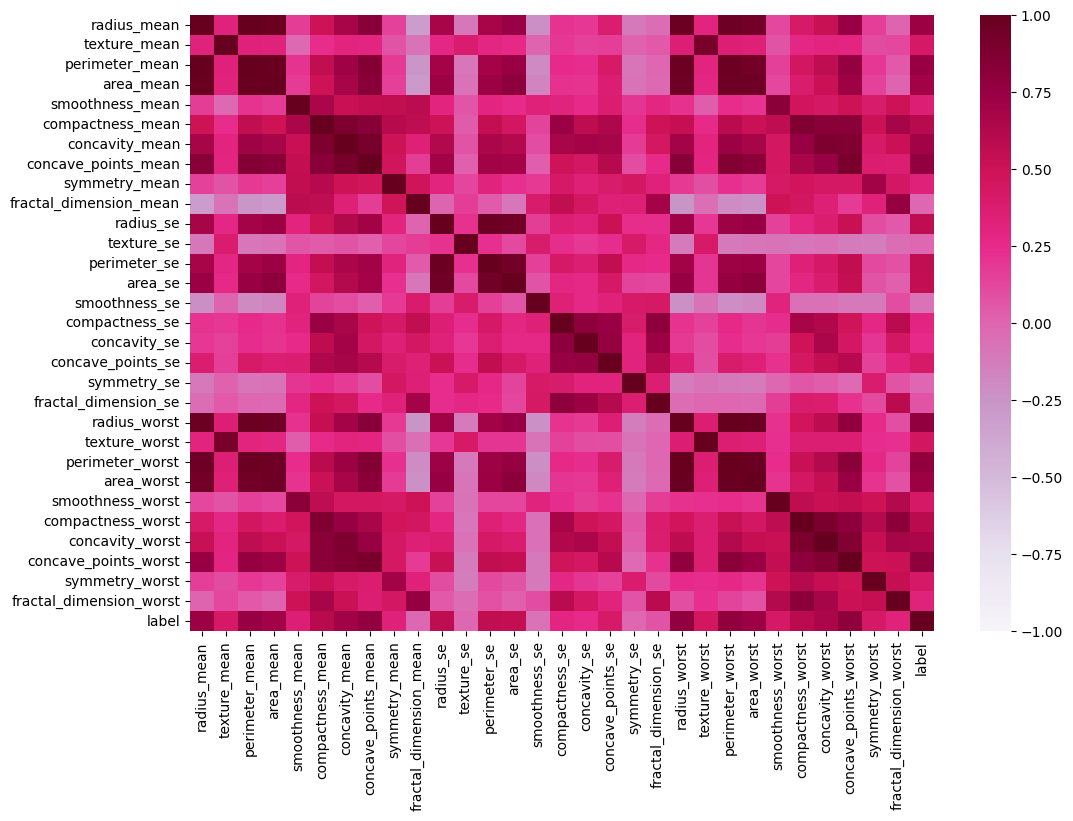

In [27]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    wbc_df.corr(numeric_only=True, method="pearson"),
    annot=False,
    cmap="PuRd",
    vmin=-1,
    vmax=1,
    center=0
)

plt.show()

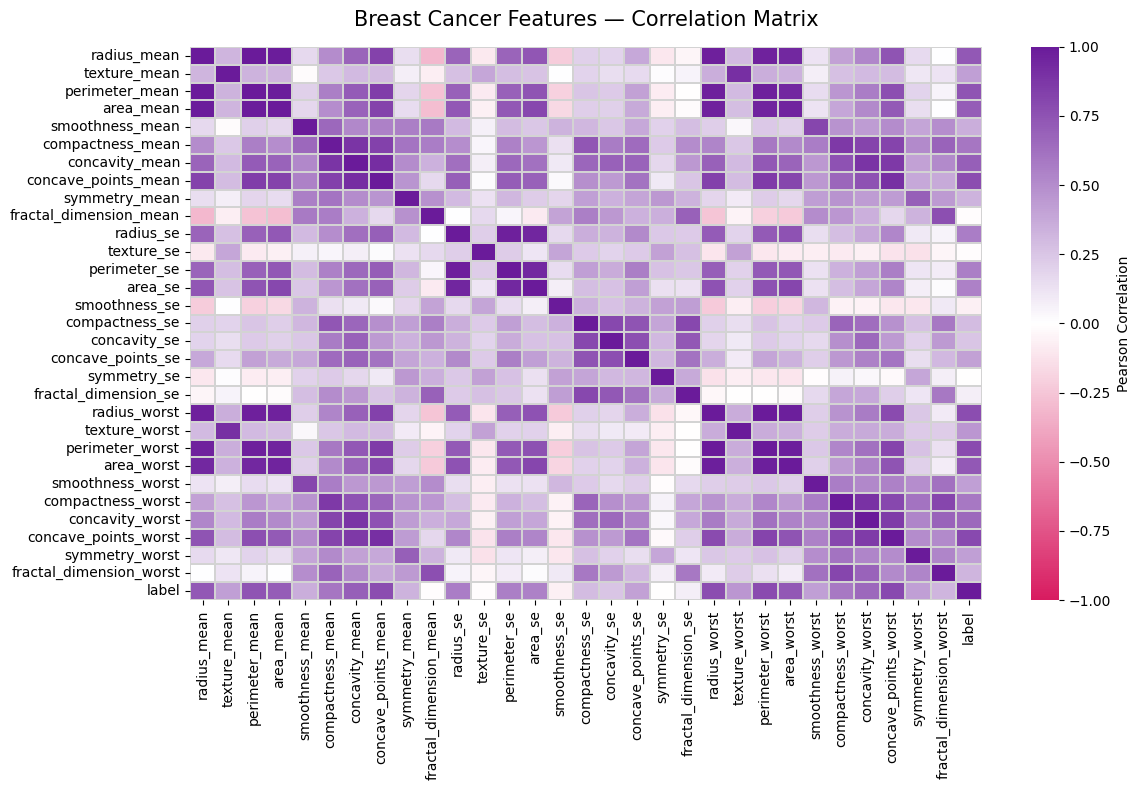

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Create a custom pink-white-purple colormap
pink_purple = LinearSegmentedColormap.from_list(
    "pink_white_purple",
    ["#D81B60", "#FFFFFF", "#6A1B9A"]
)

plt.figure(figsize=(12, 8))

sns.heatmap(
    wbc_df.corr(numeric_only=True, method="pearson"),
    annot=False,
    cmap=pink_purple,
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.3,
    linecolor="lightgray",
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title(
    "Breast Cancer Features — Correlation Matrix",
    fontsize=15,
    pad=15
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Model Training

In [21]:
# Split the data into train and test set
train_df, test_df = spark_df.randomSplit(
    [0.80, 0.20],
    seed=42
)

print("Training records:", train_df.count())
print("Testing records:", test_df.count())

Training records: 474
Testing records: 95


In [22]:
# Assemble the features and scale them

assembler = VectorAssembler(
    inputCols=feature_names,
    outputCol="features",
    handleInvalid="error"
)

scaler = StandardScaler(
    inputCol="features",
    outputCol="scaled_features",
    withMean=True,
    withStd=True
)



In [23]:
# Fit the model using Logistic Regression algorithm
lr = LogisticRegression(
    featuresCol="scaled_features",
    labelCol="label",
    maxIter=100,
    regParam=0.01,
    elasticNetParam=0.0,
    threshold=0.5
)

pipeline = Pipeline(stages=[assembler, scaler, lr])

pipeline_model = pipeline.fit(train_df)

print("PySpark model training completed.")

PySpark model training completed.


In [24]:
# Evalaute the model
predictions = pipeline_model.transform(test_df)

predictions.select(
    "label",
    "prediction",
    "probability"
).show(10, truncate=False)

# Area under the ROC curve
auc_evaluator = BinaryClassificationEvaluator(
    labelCol="label",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

auc = auc_evaluator.evaluate(predictions)
print(f"ROC-AUC: {auc:.4f}")

# Collect only the predictions and labels for detailed evaluation
evaluation_df = predictions.select(
    "label", "prediction"
).toPandas()

y_true = evaluation_df["label"].astype(int)
y_pred = evaluation_df["prediction"].astype(int)

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Benign", "Malignant"],
        zero_division=0
    )
)

malignant_recall = recall_score(
    y_true, y_pred, pos_label=1, zero_division=0
)

malignant_precision = precision_score(
    y_true, y_pred, pos_label=1, zero_division=0
)

malignant_f1 = f1_score(
    y_true, y_pred, pos_label=1, zero_division=0
)

print(f"Malignant recall:    {malignant_recall:.4f}")
print(f"Malignant precision: {malignant_precision:.4f}")
print(f"Malignant F1-score:  {malignant_f1:.4f}")

+-----+----------+------------------------------------------+
|label|prediction|probability                               |
+-----+----------+------------------------------------------+
|0    |0.0       |[0.998046206463133,0.0019537935368669768] |
|0    |0.0       |[0.9986331672412747,0.0013668327587252893]|
|0    |0.0       |[0.9999523545235658,4.7645476434210465E-5]|
|0    |0.0       |[0.9994054743320104,5.94525667989565E-4]  |
|0    |0.0       |[0.9993945990875482,6.05400912451759E-4]  |
|0    |0.0       |[0.9986440927612953,0.0013559072387047122]|
|0    |0.0       |[0.9990091192818069,9.908807181930879E-4] |
|0    |0.0       |[0.9996182410182173,3.817589817827205E-4] |
|0    |0.0       |[0.9946183918595529,0.005381608140447081] |
|0    |0.0       |[0.9973104925824616,0.0026895074175383726]|
+-----+----------+------------------------------------------+
only showing top 10 rows
ROC-AUC: 1.0000

Confusion matrix:
[[63  2]
 [ 0 30]]

Classification report:
              precision    re

In [25]:
# Prepare the data for deployment and download as a pickle file
# Extract the fitted stages from the Spark pipeline
scaler_model = pipeline_model.stages[1]
lr_model = pipeline_model.stages[2]

# Export the learned parameters
model_artifact = {
    "model_type": "PySpark Logistic Regression",
    "feature_names": feature_names,
    "scaler_mean": scaler_model.mean.toArray(),
    "scaler_std": scaler_model.std.toArray(),
    "coefficients": lr_model.coefficients.toArray(),
    "intercept": float(lr_model.intercept),
    "threshold": 0.5,
    "target_mapping": {
        "benign": 0,
        "malignant": 1
    }
}

# Save the deployment artifact
output_file = "breast_cancer_model.pkl"

joblib.dump(model_artifact, output_file)

print(f"Model artifact saved: {output_file}")
print(f"File size: {os.path.getsize(output_file):,} bytes")

# Download to your computer
files.download(output_file)

Model artifact saved: breast_cancer_model.pkl
File size: 1,779 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
# Load the artifact as a deployment application would
loaded_model = joblib.load("breast_cancer_model.pkl")

# Take test examples in the exact training feature order
X_test = test_df.select(feature_names).toPandas()

X = X_test[loaded_model["feature_names"]].to_numpy(dtype=float)

# Reproduce the fitted standardization
means = loaded_model["scaler_mean"]
stds = loaded_model["scaler_std"]

# Protect against division by zero
stds = np.where(stds == 0, 1.0, stds)

X_scaled = (X - means) / stds

# Logistic Regression probability calculation
scores = (
    X_scaled @ loaded_model["coefficients"]
    + loaded_model["intercept"]
)

# Numerically stable sigmoid
probabilities = 1.0 / (1.0 + np.exp(-np.clip(scores, -500, 500)))

# Apply the saved decision threshold
predicted_labels = (
    probabilities >= loaded_model["threshold"]
).astype(int)

print("First 10 predicted labels:", predicted_labels[:10])
print("First 10 malignant probabilities:", probabilities[:10].round(4))

First 10 predicted labels: [0 0 0 0 0 0 0 0 0 0]
First 10 malignant probabilities: [0.002  0.0014 0.     0.0006 0.0006 0.0014 0.001  0.0004 0.0054 0.0027]


In [ ]:
%pwd
# !pwd

'/content/drive/MyDrive/AI_DS_ML PROJECTS/BREAST CANCER WISCONSIN'

In [32]:
%cd "/content/drive/MyDrive/AI_DS_ML PROJECTS/BREAST CANCER WISCONSIN/"

# os.chdir("/content/drive/MyDrive/AI_DS_ML PROJECTS/BREAST CANCER WISCONSIN/")

/content/drive/MyDrive/AI_DS_ML PROJECTS/BREAST CANCER WISCONSIN


In [40]:
%ls -la
# !ls -la


total 624
drwx------   4 root root   4096 Oct 21 13:05  ./
drwx------ 114 root root   4096 Sep 12 05:46  ../
-rw-------   1 root root  13596 Oct 23 14:56  bcw_app.ipynb
-rw-------   1 root root 480410 Oct 23 14:59  BCW.ipynb
-rw-------   1 root root   1779 Oct 23 09:10  breast_cancer_model.pkl
-rw-------   1 root root    181 Oct 23 14:25 '.ignore_material - to del.gdoc'
drwx------   2 root root   4096 Oct 23 14:21  IMAGES/
drwx------   2 root root   4096 Oct 23 14:25  RAW_DATA/
-rw-------   1 root root    181 Oct 23 14:39 'ReadMe Material.gdoc'
-rw-------   1 root root 124103 Jun 20  2023  wdbc.data
